#### Teoría de los Circuitos 2
# Trabajo semanal 9
#### Leandro Robledo

1) Dada la siguiente transferencia de tensiones:

![tranferencia_punto1](Tpt1.PNG) 

a) [Sintetizar el cuadripolo pasivo sin pérdidas. Considerar Rg=1](#v2/vg)

b) Hallar el valor de k que cumple con la síntesis y valor de los componentes hallados.

2) Dada la siguiente transferencia de tension-corriente:

![tranferencia_punto2](Tpt2.PNG) 

a) [Sintetizar el cuadripolo pasivo sin pérdidas.] (#v2/ig)

b) Hallar el valor de k que cumple con la síntesis y valor de los componentes hallados.

3) Dada la siguiente transferencia de tension-corriente:

![tranferencia_punto3](Tpt3.PNG) 

a) [Sintetizar el cuadripolo pasivo sin pérdidas.] (#v3/ig)

b) Hallar el valor de [k para obtener -6 dB en el centro de la banda de paso].(#-6db)

Algunas pistas:

Revisar las metodologías presentadas para transferencias simplemente cargadas.
 
Ojo con los componentes de cierre. Prestar atención a las condiciones de medición de las restricciones (parámetros, transferencias, etc)
Verificar la topología obtenida analizando las transferencias prescritas en sus puntos clave, es decir extremos de banda, ceros de transferencia, etc.   Nota: La verificación puede facilitarse con las herramientas vistas de interconexión y conversion de parametros de cuadripolos.
Bonus

💎 [Verificar la transferencia de tension del circuito obtenido en 1)](#verificacion_1)

💎 [Verificar la transimpedancia del circuito obtenido en 2)](#verificacion_2)

🎓 [Simulación circuital del punto 1.](#simu_pt1) Medir la transferencia y comparar con la expresión de la función.  
 



### 1. Transferencia de tensiones <a id="v2/vg"></a>
Para comenzar se inicia calculando cual seria la transferencia que se deberia de cumplir de forma de dejarla expresada en funcion de una funcion de excitacion FRP (Z11) y una funcion de trasnferencia (Z21)

Luego de esto se ubican los 0 de la transferencia que deben de ser cumplidos, Luego con metodos de remocion de foster se colocan los 0 de Z11 o de su anteparte Y0= 1/Z11, de forma que con las remociones obtener el circuito correspondiente. 

![Transferencia de tensiones](Pt-1.jpeg) 

Para verificar, se calculo la el cuadripolo como una cadena de dos cuadripolos de una Impedancia en serie con una Admitancia en derivacion, una vez obtenidos se los multiplico para luego obtener el parametro A de la matriz T resultante el cual representa la inversa de la transferencia de tension buscada:
![Transferencia de tensiones](Pt-1_veri.jpeg)  <a id="verificacion_1"></a>

### 2. Transferencia de Tension-Corriente puerto de salida cargado<a id="v2/ig"></a>

Para este segundo punto se procedio de la misma forma que en anterior, buscando en este caso una trasnimpedancia por lo que en este caso la funcion de excitacion se trataba de Z22, lo que nos indica que el circuito sera armado de atras para adelante, luego se busco de igual manera cumplir los 0 de la tranferencia con remociones parciales e intermedias, obteniendo el circuito final: 
![Transferencia de tension-corriente](Pt-2.jpeg) 

Para verificar en este caso se busco obtener el parametro C ya que este referencia la transimpedancia de la funcion. Con esta verificacion se obtuvo ademas el parametro K el cual hace cumplir la transferencia original. 
![Transferencia de tension-cooriente](Pt-2_veri.jpeg)  <a id="verificacion_2"></a>

### 3. Transferencia de Tension-Corriente puerto de salida descargado<a id="v3/ig"></a>

El 3er punto se obtiene a traves de una combinacion de ambos anteriores, tratandose de una transferencia de transimpedancia pero sin carga. 
![Transferencia de tension-corriente puerto de salida descargado](Pt-3.jpeg) 
Para el punto B se obtuvo que la salida deberia de ser de la mitad de la obtenida, para eso se realizo un levantamiento parcial de masa de la bobina final ya que sobre ella recae toda la tension de salida, al dividirla en 2, se obtiene un divisor de impedancia que divide la tension exactamente en la mitad, menteniendo el funcionamiento del circuito pedido
![Transferencia de tension-cooriente salida a -6db](pt-3b.jpeg)  <a id="-6db"></a>
Para verificarlo, grafique la respuesta ideal esperada en pyton, comprobando que es la misma que la obtenida con el circuito requerido de la imagen que se encuentra debajo. Por ultimo se grafico la nueva señal (Azul) la cual pertenece al circuito con el levantamiento parcial de masa, demostrando que cumple con la misma respuesta pero esta vez disminuida -6db de la anterior

### 3B. Simulacion en Pyton<a id="simu"></a>

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Polos= [-1. +0.j        -0.5+0.8660254j -0.5-0.8660254j]


<IPython.core.display.Math object>

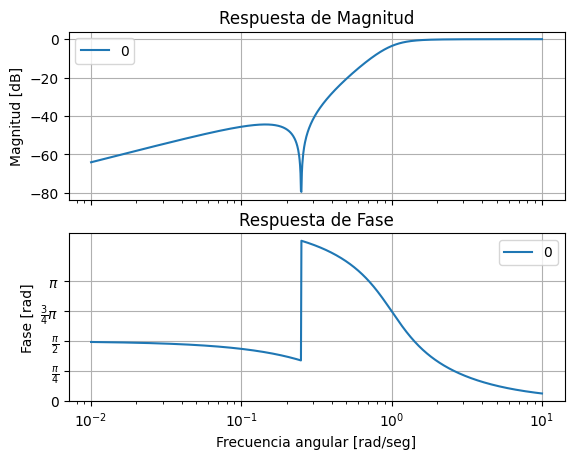

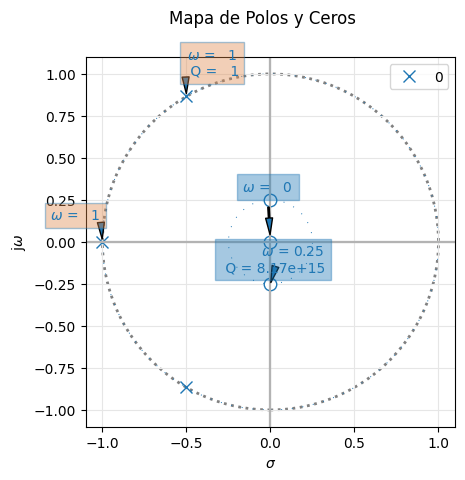

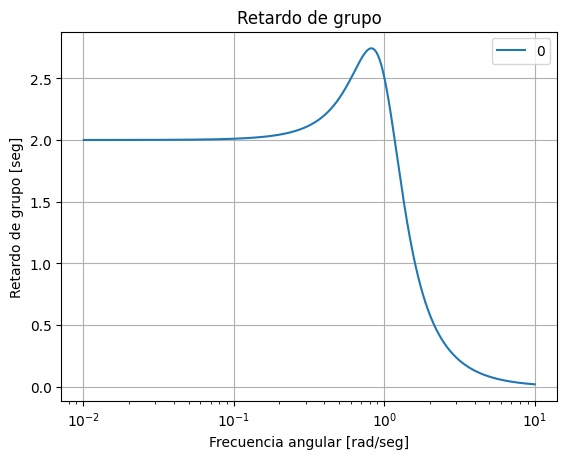

In [7]:
# Librerías externas NumPy, SciPy y Matplotlib
from scipy.signal import TransferFunction
import matplotlib.pyplot as plt
from pytc2.sistemas_lineales import pzmap, GroupDelay, bodePlot
import numpy as np
import scipy.signal as sig
from pytc2.sistemas_lineales import analyze_sys, pretty_print_bicuad_omegayq, tf2sos_analog, pretty_print_SOS
from pytc2.general import print_subtitle

num = np.array([1, 0, 1/16, 0])
den = np.array([1, 2, 2, 1 ])
p=np.roots(den)
z=np.roots(num)
k=1
print ("Polos=", p)
num, den = sig.zpk2tf(z,p,k)
mi_tf = sig.TransferFunction(num,den)
analyze_sys( mi_tf )

this_sos = tf2sos_analog(num, den)
pretty_print_SOS(this_sos, mode='omegayq')


### Bonus Simulacion de los circuitos con levantamiento parcial de masa para comparar la salida y como esta se comporta en -6db en la $\omega_0$ <a id="simu-trasnferencias"></a>
Como se observa, la trasnferencia original en verde, pasa en $\omega_0$ por -3db, como un circuito de maxima planicidad lo permitiria, mientras que el circuito con el levantamiento parcial de masa (azul) se comporta en $\omega_0$ en -9db, es decir unos 6db por debajo del primero
![Transferencias normal-levantamiento parcial de masa](Trans-6db.PNG) 
![Circuitos de la simulacion](Circ_pt3.PNG) 


### Bonus Simulacion Punto1 <a id="simu_pt1"></a>

![simulacion punto 1](simu_pt1.PNG) 

Como se observa, satisface con la simulacion de la transferencia calculada en los puntos anteriores